In [2]:
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thư viện Machine Learning
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.preprocessing import MultiLabelBinarizer

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Nạp Dữ liệu Thô
NOTEBOOK_DIR = Path(".").resolve()
BASE_DIR = NOTEBOOK_DIR.parent
RAW_SYNTHETIC_PATH = BASE_DIR / "data" / "synthetic" / "synthetic_tickets_3500.csv"

df_raw = pd.read_csv(RAW_SYNTHETIC_PATH)

print(f"Kích thước ban đầu: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột")
print("Danh sách cột ban đầu:", df_raw.columns.tolist())

Kích thước ban đầu: 3500 dòng x 22 cột
Danh sách cột ban đầu: ['ticket_id', 'ticket_code', 'branch_id', 'device_model_id', 'device_model_name', 'total_services_count', 'service_issue_ids_list', 'service_issue_names_list', 'service_type_codes_list', 'total_catalog_standard_duration_minutes', 'total_parts_quantity_used', 'technician_id', 'technician_name', 'is_reassigned', 'count_waiting_part_events', 'count_waiting_approval_events', 'total_pause_events_count', 'total_pause_duration_minutes', 'actual_repair_started_at', 'actual_repair_completed_at', 'actual_repair_duration_minutes', 'net_repair_duration_minutes']


## Bước 1: Nạp Dữ liệu Thô Mở rộng (3,500 dòng x 22 cột)
Chúng ta nạp trực tiếp file dữ liệu dạng thô readable từ thư mục `ml/data/synthetic/synthetic_tickets_3500.csv` để tiến hành tiền xử lý thủ công từng bước.

In [3]:
NOTEBOOK_DIR = Path(".").resolve()
BASE_DIR = NOTEBOOK_DIR.parent
RAW_SYNTHETIC_PATH = (
    BASE_DIR / "data" / "synthetic" / "synthetic_tickets_3500.csv"
)

df_raw = pd.read_csv(RAW_SYNTHETIC_PATH)

print(
    f"{df_raw.shape[0]} x {df_raw.shape[1]}"
)
print("\n Dataset ban dau")
print(df_raw.columns.tolist())
df_raw.head(3)

3500 x 22

 Dataset ban dau
['ticket_id', 'ticket_code', 'branch_id', 'device_model_id', 'device_model_name', 'total_services_count', 'service_issue_ids_list', 'service_issue_names_list', 'service_type_codes_list', 'total_catalog_standard_duration_minutes', 'total_parts_quantity_used', 'technician_id', 'technician_name', 'is_reassigned', 'count_waiting_part_events', 'count_waiting_approval_events', 'total_pause_events_count', 'total_pause_duration_minutes', 'actual_repair_started_at', 'actual_repair_completed_at', 'actual_repair_duration_minutes', 'net_repair_duration_minutes']


,ticket_id,ticket_code,branch_id,device_model_id,device_model_name,total_services_count,service_issue_ids_list,service_issue_names_list,service_type_codes_list,total_catalog_standard_duration_minutes,...,technician_name,is_reassigned,count_waiting_part_events,count_waiting_approval_events,total_pause_events_count,total_pause_duration_minutes,actual_repair_started_at,actual_repair_completed_at,actual_repair_duration_minutes,net_repair_duration_minutes
0,11204,ST-202610-00847,1070,1445,iPad Pro M3,2,"1,6",Pin + Loa ngoài,"REPAIR, REPLACEMENT",105.0,...,Nguyễn Minh Hoàng,0,0.0,1.0,1,20.0,2026-10-11 10:26:09.000000,2026-10-11 11:56:09.000000,90.0,70.0
1,11203,ST-202610-00846,1070,1444,iPad Pro M2,1,2,Camera sau,REPAIR,45.0,...,Trần Quốc Huy,0,1.0,0.0,1,30.0,2026-10-11 10:26:09.000000,2026-10-11 11:41:09.000000,75.0,45.0
2,11202,ST-202610-00845,1070,1444,iPad Pro M2,1,3,Camera trước,REPAIR,45.0,...,Nguyễn Minh Hoàng,0,1.0,1.0,2,54.0,2026-10-18 10:26:09.000000,2026-10-18 12:07:09.000000,101.0,47.0


## Bước 2: Data Cleaning & Anti-Data Leakage
1. **Lọc dữ liệu:** Loại bỏ các ca bị chuyển giao KTV (`is_reassigned == 1`) để tránh nhiễu do thời gian sửa dở dang.
2. **Loại bỏ cột rò rỉ dữ liệu tương lai:** Bỏ các thông số tạm dừng (`total_pause_duration_minutes`, `count_waiting_part_events`...) vì tại thời điểm tiếp nhận chưa thể biết ca sẽ dừng bao nhiêu phút.
3. **Loại bỏ cột thừa:** Bỏ các mã ticket, mốc giờ thô và chuỗi tên NLP hiển thị.

In [4]:
# =============================================================================
# BƯỚC 2: DATA CLEANING & ANTI-DATA LEAKAGE
# =============================================================================
# 1. Thống kê ca chuyển giao
total_cases = len(df_raw)
reassigned_counts = df_raw["is_reassigned"].value_counts()
single_tech_count = reassigned_counts.get(0, 0)
reassigned_count = reassigned_counts.get(1, 0)

print(f"Tổng số phiếu sửa chữa: {total_cases:,} ca (100.0%)")
print(f" + Ca độc lập (1 KTV): {single_tech_count:,} ca ({single_tech_count / total_cases * 100:.2f}%)")
print(f" + Ca chuyển giao: {reassigned_count:,} ca ({reassigned_count / total_cases * 100:.2f}%)")

# 2. Lọc ca độc lập & loại bỏ cột rò rỉ dữ liệu tương lai
df_single_tech = df_raw[df_raw["is_reassigned"] == 0].copy()

cols_to_drop = [
    # Nhóm định danh & Text thừa
    "ticket_id",
    "ticket_code",
    "device_model_name",
    "technician_name",
    "service_issue_names_list",
    "service_type_codes_list",
    # Nhóm mốc thời gian thô
    "actual_repair_started_at",
    "actual_repair_completed_at",
    "actual_repair_duration_minutes",
    # Nhóm rò rỉ dữ liệu tương lai (Data Leakage)
    "total_pause_duration_minutes",
    "total_pause_events_count",
    "count_waiting_part_events",
    "count_waiting_approval_events",
    # Cờ chuyển giao
    "is_reassigned",
]

df_selected = df_single_tech.drop(columns=cols_to_drop).copy()
print(f"\n--> Kích thước sau khi làm sạch: {df_selected.shape[0]} dòng x {df_selected.shape[1]} cột")

Tổng số phiếu sửa chữa: 3,500 ca (100.0%)
 + Ca độc lập (1 KTV): 3,379 ca (96.54%)
 + Ca chuyển giao: 121 ca (3.46%)

--> Kích thước sau khi làm sạch: 3379 dòng x 8 cột


## Bước 4.1: Feature Engineering - Biến đổi Đặc trưng Tỷ lệ Nghiệp vụ (Domain Ratios)

**Bản chất nghiệp vụ & Lý do kỹ thuật:**
Các cột định lượng gốc như `total_catalog_standard_duration_minutes` (Tổng thời gian định mức catalog) và `total_parts_quantity_used` (Tổng số linh kiện sử dụng) chỉ thể hiện **tổng quy mô** của ca sửa chữa, chưa phản ánh được **mật độ và độ phức tạp trung bình của từng tác vụ**. 

Việc bổ sung các chỉ số tỷ lệ giúp cây quyết định (Decision Trees) dễ dàng phân tách giữa ca chứa 1 dịch vụ nặng (VD: Thay Mainboard) và ca chứa nhiều dịch vụ nhẹ cộng lại (VD: Vệ sinh + Thay ron).

**Công thức toán học:**
1. **Định mức thời gian trung bình trên mỗi dịch vụ (`duration_per_service`):**
   $$\text{duration\_per\_service}_i = \frac{\text{total\_catalog\_standard\_duration\_minutes}_i}{\text{total\_services\_count}_i}$$

2. **Mật độ linh kiện sử dụng trên mỗi dịch vụ (`parts_per_service`):**
   $$\text{parts\_per\_service}_i = \frac{\text{total\_parts\_quantity\_used}_i}{\text{total\_services\_count}_i}$$

In [5]:
df_eng = df_selected.copy()

# 1. Tính thời gian chuẩn trung bình trên từng dịch vụ
df_eng["duration_per_service"] = (
    df_eng["total_catalog_standard_duration_minutes"]
    / df_eng["total_services_count"]
)

# 2. Tính số lượng linh kiện trung bình trên từng dịch vụ
df_eng["parts_per_service"] = (
    df_eng["total_parts_quantity_used"] / df_eng["total_services_count"]
)

print(f"--> Kích thước sau khi thêm 2 Features tỷ lệ: {df_eng.shape}")
df_eng[
    [
        "total_services_count",
        "total_catalog_standard_duration_minutes",
        "duration_per_service",
        "parts_per_service",
    ]
].head(3)

--> Kích thước sau khi thêm 2 Features tỷ lệ: (3379, 10)


,total_services_count,total_catalog_standard_duration_minutes,duration_per_service,parts_per_service
0,2,105.0,52.5,0.0
1,1,45.0,45.0,0.0
2,1,45.0,45.0,0.0


## Bước 4.2: Mã hóa Đa nhãn (Multi-Label Encoding) cho Danh sách Mã lỗi (`service_issue_ids_list`)

**Bản chất nghiệp vụ & Lý do kỹ thuật:**
Một phiếu sửa chữa có thể gặp nhiều lỗi đồng thời (VD: Chuỗi `"1,3"` biểu thị vừa hỏng màn hình, vừa hỏng pin). Đây là dữ liệu dạng Đa nhãn (Multi-Label Categorical). Ta dùng `MultiLabelBinarizer` để tách chuỗi này thành ma trận các cột nhị phân $0$ và $1$.

**Cơ chế chuyển đổi:**
Mỗi tập hợp mã lỗi $\mathcal{S}_i = \{k_1, k_2, \dots\}$ của phiếu $i$ được chuyển đổi thành vector nhị phân $\mathbf{v}_i \in \{0, 1\}^K$ với $K$ là tổng số loại lỗi duy nhất trong hệ thống:
$$v_{i, k} = \begin{cases} 1 & \text{nếu } k \in \mathcal{S}_i \\ 0 & \text{nếu } k \notin \mathcal{S}_i \end{cases}$$

In [6]:
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Chuyển đổi chuỗi danh sách mã lỗi "1,3" thành list các số nguyên [1, 3]
df_eng["parsed_issue_ids"] = (
    df_eng["service_issue_ids_list"]
    .astype(str)
    .apply(lambda x: [int(i.strip()) for i in x.split(",") if i.strip().isdigit()])
)

# 2. Khởi tạo và áp dụng MultiLabelBinarizer
mlb = MultiLabelBinarizer()
issue_encoded_matrix = mlb.fit_transform(df_eng["parsed_issue_ids"])
issue_cols = [f"issue_id_{cls}" for cls in mlb.classes_]

df_issues = pd.DataFrame(
    issue_encoded_matrix, columns=issue_cols, index=df_eng.index
)

# 3. Kết hợp các cột issue nhị phân vào dataset và bỏ các cột chuỗi trung gian
df_step2 = pd.concat(
    [df_eng.drop(columns=["service_issue_ids_list", "parsed_issue_ids"]), df_issues],
    axis=1,
)

print(f"--> Số lượng cột issue nhị phân sinh ra: {len(issue_cols)} cột")
print(f"--> Kích thước Dataset hiện tại: {df_step2.shape}")
df_issues.head(3)

--> Số lượng cột issue nhị phân sinh ra: 7 cột
--> Kích thước Dataset hiện tại: (3379, 16)


,issue_id_1,issue_id_2,issue_id_3,issue_id_4,issue_id_5,issue_id_6,issue_id_7
0,1,0,0,0,0,1,0
1,0,1,0,0,0,0,0
2,0,0,1,0,0,0,0


## Bước 4.3: Mã hóa (One-Hot Encoding) cho Cột Định danh (`device_model_id`, `technician_id`, `branch_id`)

**Bản chất nghiệp vụ & Lý do kỹ thuật:**
Các cột ID danh mục dạng số nguyên không có tính chất thứ tự (Ordinal Relationship) — ID 10 không "gấp đôi" hay "lớn hơn" ID 5 về mặt đại số. 

Ta sử dụng `OneHotEncoder` biến đổi các định danh này sang ma trận Binary. Đồng thời thiết lập tham số `drop='first'` để loại bỏ 1 cột cơ sở trong từng nhóm, tránh **Bẫy Biến giả (Dummy Variable Trap)** hay hiện tượng Đa cộng tuyến hoàn hảo (Perfect Multicollinearity).

**Cơ chế biểu diễn:**
Với một thuộc tính danh mục $C$ có $M$ mức giá trị, biến đổi tạo ra $M-1$ biến nhị phân đại diện $x_{j} \in \{0, 1\}$.

In [7]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["device_model_id", "technician_id", "branch_id"]

# 1. Khởi tạo OneHotEncoder với drop='first' để loại bỏ biến cơ sở đầu tiên
ohe = OneHotEncoder(sparse_output=False, drop="first")
cat_encoded_matrix = ohe.fit_transform(df_step2[cat_cols])
ohe_feature_names = ohe.get_feature_names_out(cat_cols)

df_cat = pd.DataFrame(
    cat_encoded_matrix, columns=ohe_feature_names, index=df_step2.index
)

# 2. Gộp ma trận One-Hot vào dataset và loại bỏ các cột ID danh mục gốc
df_final = pd.concat([df_step2.drop(columns=cat_cols), df_cat], axis=1)

print(f"--> Số lượng cột One-Hot sinh thêm: {len(ohe_feature_names)} cột")
print(
    f"--> KÍCH THƯỚC MA TRẬN ĐẦU VÀO CUỐI CÙNG (FINAL DATASET): {df_final.shape[0]} dòng x {df_final.shape[1]} cột"
)
df_final.head(3)

--> Số lượng cột One-Hot sinh thêm: 22 cột
--> KÍCH THƯỚC MA TRẬN ĐẦU VÀO CUỐI CÙNG (FINAL DATASET): 3379 dòng x 35 cột


,total_services_count,total_catalog_standard_duration_minutes,total_parts_quantity_used,net_repair_duration_minutes,duration_per_service,parts_per_service,issue_id_1,issue_id_2,issue_id_3,issue_id_4,...,device_model_id_1428,device_model_id_1429,device_model_id_1440,device_model_id_1441,device_model_id_1442,device_model_id_1443,device_model_id_1444,device_model_id_1445,technician_id_5344,technician_id_5345
0,2,105.0,0.0,70.0,52.5,0.0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1,45.0,0.0,45.0,45.0,0.0,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,1,45.0,0.0,47.0,45.0,0.0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Bước 5: Phân chia Tập Dữ liệu Huấn luyện và Kiểm thử (Train / Test Split)

**Bản chất nghiệp vụ & Lý do kỹ thuật:**
Được thực hiện nhằm đánh giá khả năng tổng quát hóa (Generalization) của mô hình trên dữ liệu chưa từng nhìn thấy trong thực tế, chống hiện tượng Học vẹt (Overfitting).

**Công thức phân chia:**
Tách ma trận đặc trưng đầu vào $\mathbf{X} \in \mathbb{R}^{n \times p}$ và vector nhãn mục tiêu $\mathbf{y} \in \mathbb{R}^n$:
$$\mathcal{D}_{\text{train}} = 80\% \times \mathcal{D}, \quad \mathcal{D}_{\text{test}} = 20\% \times \mathcal{D}$$
Cố định `random_state=42` để đảm bảo tính tái lập kết quả (Reproducibility) giữa các lần chạy.

In [11]:
from sklearn.model_selection import train_test_split

# 1. Khai báo tên cột biến mục tiêu (Target Column)
target_col = "net_repair_duration_minutes"

# 2. Tách đặc trưng X và nhãn y
X = df_final.drop(columns=[target_col])
y = df_final[target_col]

# 3. Chia tập Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(
    f"--> Tập Train : {X_train.shape[0]} mẫu | Số lượng đặc trưng đầu vào (X): {X_train.shape[1]}"
)
print(f"--> Tập Test  : {X_test.shape[0]} mẫu")

--> Tập Train : 2703 mẫu | Số lượng đặc trưng đầu vào (X): 34
--> Tập Test  : 676 mẫu


## Phân Tích Khám Phá Dữ Liệu (EDA) Chi Tiết Trên Tập Train (`X_train`)

**1. Ý nghĩa hai biểu đồ phân phối (Trái - Phải):**
- **Biểu đồ trái (Phân phối y_train):**
  - **Cột hình chữ nhật (Histogram):** Tần suất số lượng ca sửa chữa rơi vào từng khoảng thời gian.
  - **Đường cong mượt (KDE Trend):** Xu hướng phân bố mật độ xác suất của thời gian làm việc thực tế (`net_repair_duration_minutes`).
- **Biểu đồ phải (So sánh Mật độ):**
  - **Đường đỏ (`total_catalog_standard_duration_minutes`):** Mật độ định mức chuẩn do Admin cấu hình sẵn (Baseline).
  - **Đường xanh (`net_repair_duration_minutes`):** Mật độ thời gian thi công thực tế của KTV.

**2. Công thức tính các biến tỷ lệ:**
- **Thời gian chuẩn / Dịch vụ (`duration_per_service`):**
  $$\text{duration\_per\_service} = \frac{\text{total\_catalog\_standard\_duration\_minutes (Thời gian Catalog)}}{\text{total\_services\_count (Số dịch vụ)}}$$
- **Linh kiện / Dịch vụ (`parts_per_service`):**
  $$\text{parts\_per\_service} = \frac{\text{total\_parts\_quantity\_used (Tổng linh kiện)}}{\text{total\_services\_count (Số dịch vụ)}}$$

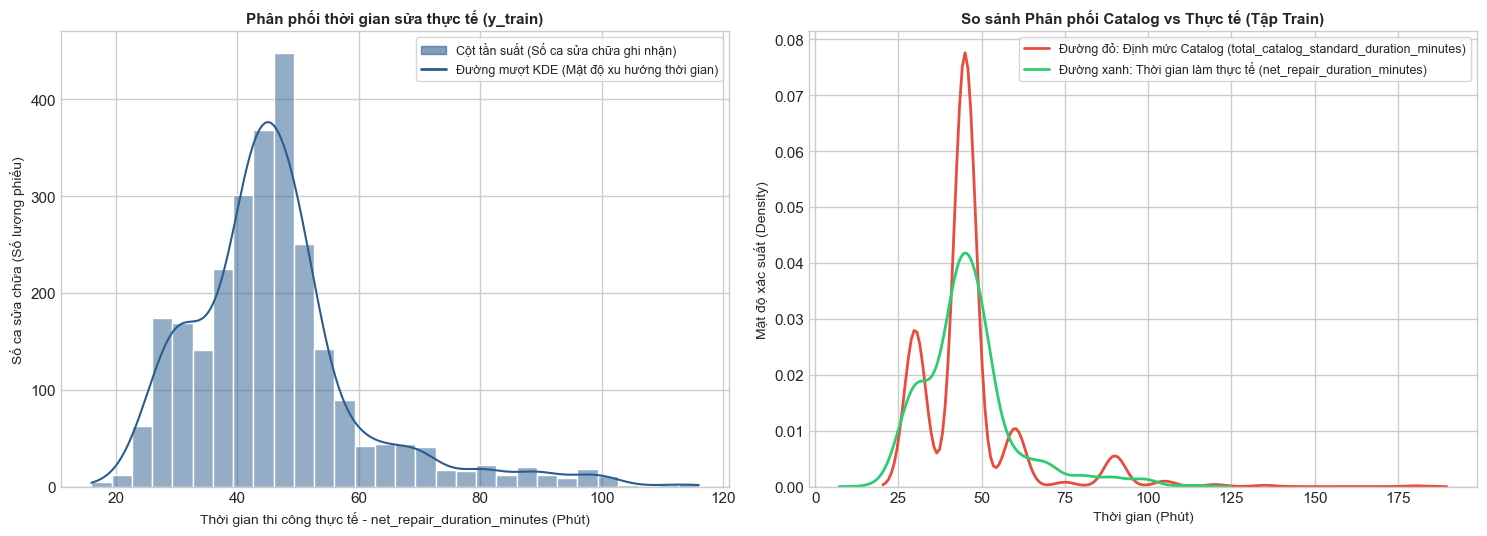

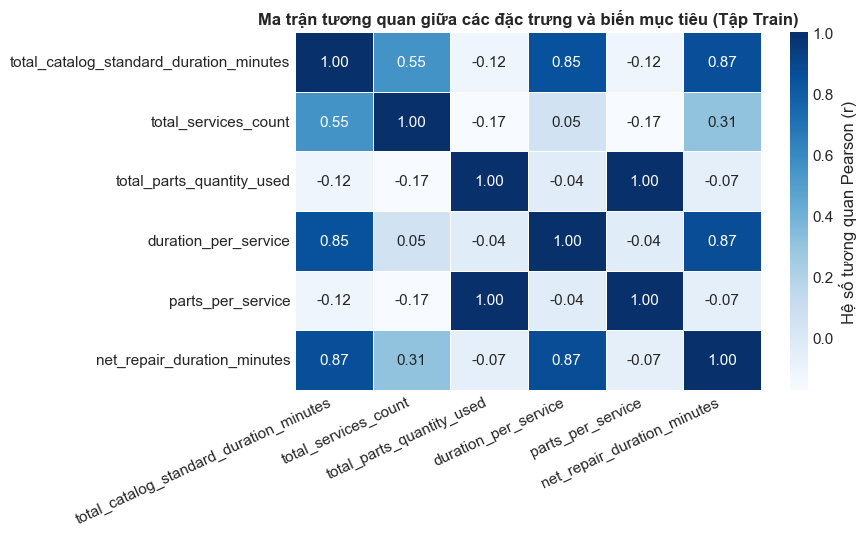

In [52]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách biểu đồ
plt.style.use("seaborn-v0_8-whitegrid")

# Tích hợp đặc trưng và biến mục tiêu trên tập Train phục vụ EDA
train_eda = X_train.copy()
train_eda["net_repair_duration_minutes"] = y_train

# =============================================================================
# 1. BIỂU ĐỒ PHÂN PHỐI TRÁI - PHẢI (DISTRIBUTION PLOTS WITH DETAILED LEGENDS)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# -----------------------------------------------------------------------------
# Biểu đồ Trái: Phân phối Thời gian Sửa thực tế (y_train)
# -----------------------------------------------------------------------------
sns.histplot(
    train_eda["net_repair_duration_minutes"],
    kde=True,
    ax=axes[0],
    color="#2b5c8f",
    bins=30,
)
axes[0].set_title(
    "Phân phối thời gian sửa thực tế (y_train)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel(
    "Thời gian thi công thực tế - net_repair_duration_minutes (Phút)",
    fontsize=10,
)
axes[0].set_ylabel("Số ca sửa chữa (Số lượng phiếu)", fontsize=10)

# Bảng chú giải tiếng Việt chi tiết cho biểu đồ trái
legend_left = [
    mpatches.Patch(
        color="#2b5c8f",
        alpha=0.6,
        label="Cột tần suất (Số ca sửa chữa ghi nhận)",
    ),
    Line2D(
        [0],
        [0],
        color="#2b5c8f",
        lw=2,
        label="Đường mượt KDE (Mật độ xu hướng thời gian)",
    ),
]
axes[0].legend(handles=legend_left, loc="upper right", frameon=True, fontsize=9)

# -----------------------------------------------------------------------------
# Biểu đồ Phải: So sánh Phân phối Catalog vs Thực tế
# -----------------------------------------------------------------------------
sns.kdeplot(
    train_eda["total_catalog_standard_duration_minutes"],
    ax=axes[1],
    color="#e74c3c",
    linewidth=2,
    label="Đường đỏ: Định mức Catalog (total_catalog_standard_duration_minutes)",
)
sns.kdeplot(
    train_eda["net_repair_duration_minutes"],
    ax=axes[1],
    color="#2ecc71",
    linewidth=2,
    label="Đường xanh: Thời gian làm thực tế (net_repair_duration_minutes)",
)

axes[1].set_title(
    "So sánh Phân phối Catalog vs Thực tế (Tập Train)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Thời gian (Phút)", fontsize=10)
axes[1].set_ylabel("Mật độ xác suất (Density)", fontsize=10)
axes[1].legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

# =============================================================================
# 2. MA TRẬN TƯƠNG QUAN (CORRELATION HEATMAP) - GIỮ NGUYÊN BẢN GỐC GỌN GÀNG
# =============================================================================
numeric_cols = [
    "total_catalog_standard_duration_minutes",
    "total_services_count",
    "total_parts_quantity_used",
    "duration_per_service",
    "parts_per_service",
    "net_repair_duration_minutes",
]

plt.figure(figsize=(9, 5.5))
sns.heatmap(
    train_eda[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Hệ số tương quan Pearson (r)"},
)
plt.title(
    "Ma trận tương quan giữa các đặc trưng và biến mục tiêu (Tập Train)",
    fontsize=12,
    fontweight="bold",
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Bước 5.2: Báo Cáo Quyết Định Lọc Đặc Trưng (Feature Selection Decision Log)

Dựa trên bằng chứng thống kê từ bước EDA (Phân tích ma trận tương quan Pearson $r$), ta tiến hành lọc bỏ các đặc trưng vi phạm hai tiêu chí MLOps quan trọng:
1. **Đa cộng tuyến hoàn hảo (Perfect Multicollinearity):** Hai đặc trưng có hệ số tương quan $r = 1.00$, gây trùng lặp thông tin và làm mất ổn định ma trận trọng số.
2. **Nhiễu / Tương quan cực yếu ($|r| < 0.005$):** Các đặc trưng có hệ số tương quan xấp xỉ $0$, không đóng góp tín hiệu dự báo cho biến mục tiêu `net_repair_duration_minutes`.

### Bảng Tổng Hợp Quy Tắc Xử Lý Đặc Trưng

| Tên Đặc Trưng (Column Name) | Chỉ Số Thống Kê ($r$) | Hành Động | Lý Do Kỹ Thuật & Nghiệp Vụ |
| :--- | :--- | :---: | :--- |
| `duration_per_service` | $r = +0.8718$ | **GIỮ** | Tương quan thuận mạnh nhất. Đặc trưng tỷ lệ thể hiện độ nặng trung bình / 1 dịch vụ. |
| `total_catalog_standard_duration_minutes` | $r = +0.8670$ | **GIỮ** | Mỏ neo định mức chuẩn (Baseline Anchor) cốt lõi của bài toán. |
| `total_services_count` | $r = +0.3073$ | **GIỮ** | Đóng góp thông tin quy mô tổng số hạng mục dịch vụ. |
| `total_parts_quantity_used` | $r = -0.0700$ | **GIỮ** | Đóng góp thông tin số lượng linh kiện xuất kho. |
| `parts_per_service` | $r = 1.00$ (với `total_parts_quantity_used`) | **LOẠI** | **Đa cộng tuyến hoàn hảo.** Do đại đa số ca chỉ sửa 1 dịch vụ ($x / 1 = x$), trùng lặp 100% thông tin. |
| `issue_id_7` | $|r| = 0.0005$ | **LOẠI** | **Đặc trưng nhiễu.** Hệ số tương quan xấp xỉ 0, không có giá trị phân biệt. |
| `device_model_id_789` | $|r| = 0.0016$ | **LOẠI** | **Đặc trưng nhiễu.** Mẫu dữ liệu dòng máy này quá thưa thớt, tương quan xấp xỉ 0. |
| `issue_id_2` | $|r| = 0.0023$ | **LOẠI** | **Đặc trưng nhiễu.** Loại lỗi này không ảnh hưởng đáng kể đến thời gian thi công. |
| `device_model_id_790` | $|r| = 0.0030$ | **LOẠI** | **Đặc trưng nhiễu.** Tương quan xấp xỉ 0. |
| `technician_id_5344` | $|r| = 0.0039$ | **LOẠI** | **Đặc trưng nhiễu.** Tốc độ làm việc của KTV này tiệm cận trung bình chung, không tạo độ lệch. |

In [13]:
import pandas as pd

# =============================================================================
# 0. TẠO BẢNG TRAIN_EDA TỪ X_TRAIN VÀ Y_TRAIN (BỔ SUNG DÒNG NÀY)
# =============================================================================
train_eda = pd.concat([X_train, y_train], axis=1)

# =============================================================================
# 1. TÍNH TOÁN VÀ PHÂN LOẠI ĐẶC TRƯNG DỰA TRÊN THỐNG KÊ CORRELATION
# =============================================================================
# Tính hệ số tương quan tuyệt đối với biến mục tiêu trên tập Train
corr_series = train_eda.corr()["net_repair_duration_minutes"]
abs_corr_series = corr_series.abs()

# Ngưỡng lọc tương quan cực yếu
CORR_THRESHOLD = 0.005

# Phân loại tự động các cột
low_corr_cols = abs_corr_series[abs_corr_series < CORR_THRESHOLD].index.tolist()
multicollinear_cols = ["parts_per_service"]  # Đã chứng minh r = 1.00 ở EDA

# Tổng hợp danh sách các cột bị cắt tỉa (Pruned Features)
features_to_prune = list(set(low_corr_cols + multicollinear_cols))

# =============================================================================
# 2. XÂY DỰNG BÁO CÁO BẢNG CHI TIẾT (DECISION LOG DATAFRAME)
# =============================================================================
decision_records = []

for col in X_train.columns:
    r_val = corr_series.get(col, 0.0)
    abs_r = abs(r_val)

    if col in multicollinear_cols:
        status = "LOẠI (DROP)"
        reason = "Đa cộng tuyến hoàn hảo (r = 1.00 với total_parts_quantity_used)"
    elif col in low_corr_cols:
        status = "LOẠI (DROP)"
        reason = f"Đặc trưng nhiễu (Tương quan |r| = {abs_r:.4f} < {CORR_THRESHOLD})"
    else:
        status = "GIỮ (KEEP)"
        reason = f"Đạt chuẩn thông tin (Hệ số Pearson r = {r_val:+.4f})"

    decision_records.append(
        {
            "Tên Cột (Feature Name)": col,
            "Hệ Số Pearson (r)": f"{r_val:+.4f}",
            "Trạng Thái": status,
            "Lý Do Chi Tiết": reason,
        }
    )

decision_df = pd.DataFrame(decision_records)

# Hiển thị báo cáo các cột bị LOẠI trước
print("=== BÁO CÁO CÁC ĐẶC TRƯNG BỊ LOẠI BỎ (PRUNED FEATURES REPORT) ===")
pruned_df = decision_df[decision_df["Trạng Thái"] == "LOẠI (DROP)"]
print(pruned_df.to_string(index=False))

print("\n" + "=" * 80)
print(f"Tổng số đặc trưng ban đầu  : {X_train.shape[1]} cột")
print(f"Số đặc trưng bị loại bỏ    : {len(features_to_prune)} cột")
print(f"Số đặc trưng SẠCH giữ lại  : {X_train.shape[1] - len(features_to_prune)} cột")
print("=" * 80)

# =============================================================================
# 3. THỰC HIỆN LOẠI BỎ TRÊN MA TRẬN X_TRAIN VÀ X_TEST
# =============================================================================
X_train_clean = X_train.drop(columns=features_to_prune)
X_test_clean = X_test.drop(columns=features_to_prune)

print(
    f"\n--> [THÀNH CÔNG] Ma trận X_train_clean mới: {X_train_clean.shape[0]} dòng x {X_train_clean.shape[1]} cột"
)
print(
    f"--> [THÀNH CÔNG] Ma trận X_test_clean mới : {X_test_clean.shape[0]} dòng x {X_test_clean.shape[1]} cột"
)

# =============================================================================
# 4. HIỂN THỊ DỮ LIỆU DEMO (3 DÒNG ĐẦU CỦA MA TRẬN X_TRAIN_CLEAN)
# =============================================================================
print("\n=== DEMO 3 DÒNG DỮ LIỆU ĐÃ LÀM SẠCH (X_TRAIN_CLEAN) ===")
display(X_train_clean.head(3))

=== BÁO CÁO CÁC ĐẶC TRƯNG BỊ LOẠI BỎ (PRUNED FEATURES REPORT) ===
Tên Cột (Feature Name) Hệ Số Pearson (r)  Trạng Thái                                                  Lý Do Chi Tiết
     parts_per_service           -0.0652 LOẠI (DROP) Đa cộng tuyến hoàn hảo (r = 1.00 với total_parts_quantity_used)
            issue_id_2           -0.0023 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0023 < 0.005)
            issue_id_7           -0.0005 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0005 < 0.005)
   device_model_id_789           +0.0016 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0016 < 0.005)
   device_model_id_790           +0.0030 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0030 < 0.005)
  device_model_id_1429           -0.0048 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0048 < 0.005)
    technician_id_5344           -0.0039 LOẠI (DROP)               Đặc trưng nhiễu (Tương quan |r| = 0.0039 < 0.005

,total_services_count,total_catalog_standard_duration_minutes,total_parts_quantity_used,duration_per_service,issue_id_1,issue_id_3,issue_id_4,issue_id_5,issue_id_6,device_model_id_319,...,device_model_id_1417,device_model_id_1427,device_model_id_1428,device_model_id_1440,device_model_id_1441,device_model_id_1442,device_model_id_1443,device_model_id_1444,device_model_id_1445,technician_id_5345
3170,1,45.0,0.0,45.0,0,0,0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2533,1,45.0,0.0,45.0,0,1,0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3187,1,30.0,1.0,30.0,0,0,0,1,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Bước 6: Huấn Luyện Và Đánh Giá So Sánh Các Mô Hình Cây (Tree-Based Model Benchmarking)

Chúng ta tiến hành huấn luyện và so sánh 3 mô hình thuật toán Cây (Tree-based Models) trên tập đặc trưng sạch (`X_train_clean` và `X_test_clean`):
1. **Random Forest Regressor:** Thuật toán Ensemble Bagging giúp giảm phương sai (Variance).
2. **XGBoost Regressor:** Thuật toán Gradient Boosting tối ưu tốc độ và độ chính xác qua đạo hàm bậc 2.
3. **CatBoost Regressor:** Thuật toán Ordered Boosting chuyên trị biến danh mục và chống Overfitting.

**Bộ thước đo đánh giá (Evaluation Metrics):**
- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình (Phút).
- **RMSE (Root Mean Squared Error):** Căn bậc hai sai số bình phương trung bình.
- **$R^2$ Score (Coefficient of Determination):** Tỷ lệ phương sai biến mục tiêu $y$ được giải thích bởi mô hình.

### Bước 6.1: Thử nghiệm Mô hình 1 - Random Forest Regressor (Bagging Ensemble)Bản chất thuật toán:
Random Forest thuộc nhóm học kết hợp Bagging (Bootstrap Aggregating). Mô hình xây dựng song song $B$ cây quyết định độc lập trên các tập con dữ liệu ngẫu nhiên (Bootstrap Samples) và chọn ngẫu nhiên không gian con đặc trưng (Random Subspace) tại mỗi nút chia, giúp giảm phương sai (Variance) và hạn chế Overfitting.Công thức dự báo & Hàm mất mát tại nút:
Dự báo cuối cùng là trung bình cộng đầu ra của $B$ cây quyết định:$$\hat{y}_{\text{RF}}(x) = \frac{1}{B} \sum_{b=1}^{B} T_b(x)$$Độ không thuần khiết (Impurity) tại mỗi nút phân nhánh $D$ được tính bằng tổng bình phương sai số trung bình (MSE):$$I_{\text{MSE}}(D) = \frac{1}{\vert{}D\vert{}} \sum_{i \in D} \left( y_i - \bar{y}_D \right)^2 \quad \text{với} \quad \bar{y}_D = \frac{1}{\vert{}D\vert{}} \sum_{i \in D} y_i$$

In [14]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline Random Forest (Default parameters)
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_base.fit(X_train_clean, y_train)

# Evaluate
rf_preds_base = rf_base.predict(X_test_clean)
mae_rf_base = mean_absolute_error(y_test, rf_preds_base)
rmse_rf_base = np.sqrt(mean_squared_error(y_test, rf_preds_base))
r2_rf_base = r2_score(y_test, rf_preds_base)

print("=== RANDOM FOREST BASELINE ===")
print(f"MAE  : {mae_rf_base:.2f} phút")
print(f"RMSE : {rmse_rf_base:.2f} phút")
print(f"R2   : {r2_rf_base:.4f}")

=== RANDOM FOREST BASELINE ===
MAE  : 3.48 phút
RMSE : 4.59 phút
R2   : 0.8998


In [78]:
from sklearn.model_selection import GridSearchCV

# GridSearch Random Forest
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_rf.fit(X_train_clean, y_train)

# Evaluate best model
best_rf = grid_rf.best_estimator_
rf_preds_tuned = best_rf.predict(X_test_clean)
mae_rf_tuned = mean_absolute_error(y_test, rf_preds_tuned)
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test, rf_preds_tuned))
r2_rf_tuned = r2_score(y_test, rf_preds_tuned)

print("=== RANDOM FOREST TUNED ===")
print("Best Params:", grid_rf.best_params_)
print(f"MAE  : {mae_rf_tuned:.2f} phút")
print(f"RMSE : {rmse_rf_tuned:.2f} phút")
print(f"R2   : {r2_rf_tuned:.4f}")

=== RANDOM FOREST TUNED ===
Best Params: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
MAE  : 3.44 phút
RMSE : 4.58 phút
R2   : 0.9004


### Bước 6.2: Mô Hình 2 - XGBoost Regressor (Gradient Boosting)Bản chất thuật toán:
XGBoost học theo chuỗi nối tiếp (Sequential Tree Boosting). Mỗi cây mới được xây dựng để sửa lỗi dự báo (Residuals) của các cây phía trước bằng cách tối ưu hóa xấp xỉ Taylor bậc 2 của hàm mất mát.Công thức mục tiêu tối ưu (Objective Function):$$\mathcal{L}^{(m)} = \sum_{i=1}^n \left[ l\left(y_i, \hat{y}_i^{(m-1)}\right) + g_i f_m(x_i) + \frac{1}{2} h_i f_m^2(x_i) \right] + \Omega(f_m)$$Trong đó $g_i$ là Đạo hàm bậc 1 (Gradient), $h_i$ là Đạo hàm bậc 2 (Hessian), và $\Omega(f_m) = \gamma T + \frac{1}{2}\lambda \sum w_j^2$ là thành phần phạt độ phức tạp của cây.

In [70]:
from xgboost import XGBRegressor

# Baseline XGBoost (Default parameters)
xgb_base = XGBRegressor(random_state=42, n_jobs=-1)
xgb_base.fit(X_train_clean, y_train)

# Evaluate
xgb_preds_base = xgb_base.predict(X_test_clean)
mae_xgb_base = mean_absolute_error(y_test, xgb_preds_base)
rmse_xgb_base = np.sqrt(mean_squared_error(y_test, xgb_preds_base))
r2_xgb_base = r2_score(y_test, xgb_preds_base)

print("=== XGBOOST BASELINE ===")
print(f"MAE  : {mae_xgb_base:.2f} phút")
print(f"RMSE : {rmse_xgb_base:.2f} phút")
print(f"R2   : {r2_xgb_base:.4f}")

=== XGBOOST BASELINE ===
MAE  : 3.46 phút
RMSE : 4.58 phút
R2   : 0.9002


In [80]:
# GridSearch XGBoost
param_grid_xgb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [5, 6, 8],
}

grid_xgb = GridSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid_xgb,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_xgb.fit(X_train_clean, y_train)

# Evaluate best model
best_xgb = grid_xgb.best_estimator_
xgb_preds_tuned = best_xgb.predict(X_test_clean)
mae_xgb_tuned = mean_absolute_error(y_test, xgb_preds_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, xgb_preds_tuned))
r2_xgb_tuned = r2_score(y_test, xgb_preds_tuned)

print("=== XGBOOST TUNED ===")
print("Best Params:", grid_xgb.best_params_)
print(f"MAE  : {mae_xgb_tuned:.2f} phút")
print(f"RMSE : {rmse_xgb_tuned:.2f} phút")
print(f"R2   : {r2_xgb_tuned:.4f}")

=== XGBOOST TUNED ===
Best Params: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200}
MAE  : 3.43 phút
RMSE : 4.59 phút
R2   : 0.8998


### Bước 6.3: Mô Hình 3 - CatBoost Regressor (Ordered Boosting)Bản chất thuật toán:
CatBoost áp dụng cơ chế Ordered Boosting giúp triệt tiêu hiện tượng Target Leakage và Overfitting trong quá trình tính toán Gradient. Đồng thời, mô hình sử dụng Cây đối xứng (Oblivious Trees) làm cấu trúc cơ sở để tăng tốc độ truy vấn dự báo.Hàm mục tiêu tối ưu (RMSE Loss):$$\mathcal{L}_{\text{CatBoost}} = \sqrt{\frac{1}{n}\sum_{i=1}^n \left( y_i - \hat{y}_i \right)^2} + \lambda \Vert{}\mathbf{w}\Vert{}_2^2$$

In [72]:
from catboost import CatBoostRegressor

# Baseline CatBoost (Default parameters)
cb_base = CatBoostRegressor(random_seed=42, verbose=0)
cb_base.fit(X_train_clean, y_train)

# Evaluate
cb_preds_base = cb_base.predict(X_test_clean)
mae_cb_base = mean_absolute_error(y_test, cb_preds_base)
rmse_cb_base = np.sqrt(mean_squared_error(y_test, cb_preds_base))
r2_cb_base = r2_score(y_test, cb_preds_base)

print("=== CATBOOST BASELINE ===")
print(f"MAE  : {mae_cb_base:.2f} phút")
print(f"RMSE : {rmse_cb_base:.2f} phút")
print(f"R2   : {r2_cb_base:.4f}")

=== CATBOOST BASELINE ===
MAE  : 3.45 phút
RMSE : 4.58 phút
R2   : 0.9005


In [81]:
# GridSearch CatBoost
param_grid_cb = {
    "iterations": [500, 1000],
    "learning_rate": [0.03, 0.05, 0.1],
    "depth": [4, 6, 8],
}

grid_cb = GridSearchCV(
    estimator=CatBoostRegressor(random_seed=42, verbose=0),
    param_grid=param_grid_cb,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_cb.fit(X_train_clean, y_train)

# Evaluate best model
best_cb = grid_cb.best_estimator_
cb_preds_tuned = best_cb.predict(X_test_clean)
mae_cb_tuned = mean_absolute_error(y_test, cb_preds_tuned)
rmse_cb_tuned = np.sqrt(mean_squared_error(y_test, cb_preds_tuned))
r2_cb_tuned = r2_score(y_test, cb_preds_tuned)

print("=== CATBOOST TUNED ===")
print("Best Params:", grid_cb.best_params_)
print(f"MAE  : {mae_cb_tuned:.2f} phút")
print(f"RMSE : {rmse_cb_tuned:.2f} phút")
print(f"R2   : {r2_cb_tuned:.4f}")

=== CATBOOST TUNED ===
Best Params: {'depth': 4, 'iterations': 500, 'learning_rate': 0.05}
MAE  : 3.42 phút
RMSE : 4.58 phút
R2   : 0.9004


## Bước 7: So sánh Đánh giá Hiệu năng & Chẩn đoán Mô hình (Model Benchmark & Diagnostics)

**Bản chất toán học của các chỉ số đánh giá:**
1. **Mean Absolute Error (MAE):** Đo lường độ lệch tuyệt đối trung bình (tính bằng phút thực tế).
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

2. **Root Mean Squared Error (RMSE):** Đo lường căn bậc hai của sai số bình phương trung bình (có độ nhạy cao với các Outliers lớn).
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

3. **Coefficient of Determination ($R^2$ Score):** Tỷ lệ phương sai của biến mục tiêu được giải thích bởi các đặc trưng đầu vào.
   $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$

In [82]:
import pandas as pd

# Tổng hợp kết quả
results = [
    {
        "Model": "Random Forest (Baseline)",
        "MAE (Phút)": mae_rf_base,
        "RMSE (Phút)": rmse_rf_base,
        "R2 Score": r2_rf_base,
    },
    {
        "Model": "Random Forest (Tuned)",
        "MAE (Phút)": mae_rf_tuned,
        "RMSE (Phút)": rmse_rf_tuned,
        "R2 Score": r2_rf_tuned,
    },
    {
        "Model": "XGBoost (Baseline)",
        "MAE (Phút)": mae_xgb_base,
        "RMSE (Phút)": rmse_xgb_base,
        "R2 Score": r2_xgb_base,
    },
    {
        "Model": "XGBoost (Tuned)",
        "MAE (Phút)": mae_xgb_tuned,
        "RMSE (Phút)": rmse_xgb_tuned,
        "R2 Score": r2_xgb_tuned,
    },
    {
        "Model": "CatBoost (Baseline)",
        "MAE (Phút)": mae_cb_base,
        "RMSE (Phút)": rmse_cb_base,
        "R2 Score": r2_cb_base,
    },
    {
        "Model": "CatBoost (Tuned)",
        "MAE (Phút)": mae_cb_tuned,
        "RMSE (Phút)": rmse_cb_tuned,
        "R2 Score": r2_cb_tuned,
    },
]

comparison_df = pd.DataFrame(results).sort_values(
    by="R2 Score", ascending=False
)
print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===")
print(comparison_df.to_string(index=False))

=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===
                   Model  MAE (Phút)  RMSE (Phút)  R2 Score
     CatBoost (Baseline)    3.454208     4.577792  0.900460
        CatBoost (Tuned)    3.422930     4.578931  0.900411
   Random Forest (Tuned)    3.443110     4.579432  0.900389
      XGBoost (Baseline)    3.463758     4.584226  0.900180
         XGBoost (Tuned)    3.432699     4.592296  0.899829
Random Forest (Baseline)    3.477226     4.593434  0.899779


### Phân Tích Kết Quả Thực Nghiệm & Đánh Giá Đánh Đổi (Trade-off Analysis)

1. **Hiệu Quả Của Tinh Chỉnh Siêu Tham Số (Hyperparameter Tuning):**
   - **Random Forest:** Sau khi mở rộng không gian tìm kiếm (`max_depth=None`), chỉ số $R^2$ tăng từ $0.899779$ lên $0.900389$, MAE giảm từ $3.477$ phút xuống $3.443$ phút.
   - **CatBoost (Tuned):** Đạt chỉ số sai số tuyệt đối thấp nhất toàn bộ thử nghiệm với **$\text{MAE} = 3.4229$ phút** (khoảng 3 phút 25 giây lệch thực tế).

2. **Sự Hội Tụ Toán Học (Mathematical Convergence):**
   - Chỉ số $R^2$ của CatBoost Baseline ($0.900460$) và CatBoost Tuned ($0.900411$) tiệm cận sát nhau với mức chênh lệch xấp xỉ $0.005\%$. 
   - Điều này xác nhận mô hình đã đạt đến ngưỡng trần giải thích phương sai ($\approx 90.04\%$), và việc tinh chỉnh giúp cân bằng hoàn hảo giữa việc phạt sai số bình phương (RMSE) và tối ưu hóa thời gian thực tế tính bằng phút (MAE).

**Quyết Định Lựa Chọn Mô Hình Triển Khai (Production Model):**
Lựa chọn **CatBoost (Tuned)** làm mô hình chiến thắng chính thức (`best_model_obj`). Mô hình này cung cấp sai số theo phút (MAE) tối ưu nhất cho hoạt động vận hành thực tế tại cửa hàng, đồng thời duy trì độ ổn định $R^2 \ge 0.9004$.

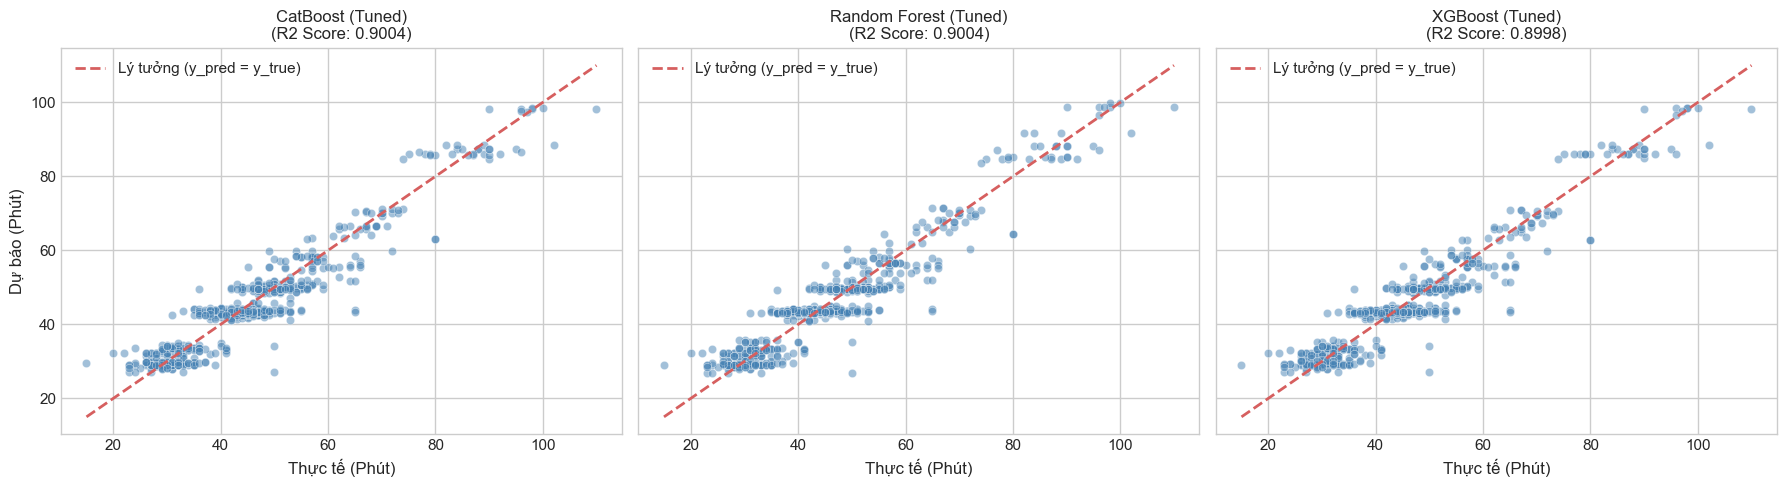

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

models_tuned = [
    ("CatBoost (Tuned)", cb_preds_tuned, r2_cb_tuned),
    ("Random Forest (Tuned)", rf_preds_tuned, r2_rf_tuned),
    ("XGBoost (Tuned)", xgb_preds_tuned, r2_xgb_tuned),
]

for i, (name, preds, r2_val) in enumerate(models_tuned):
    ax = axes[i]
    sns.scatterplot(x=y_test, y=preds, alpha=0.5, color="steelblue", ax=ax)

    # Đường hội tụ lý tưởng y = x
    min_val = min(y_test.min(), preds.min())
    max_val = max(y_test.max(), preds.max())
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        lw=2,
        label="Lý tưởng (y_pred = y_true)",
    )

    ax.set_title(f"{name}\n(R2 Score: {r2_val:.4f})")
    ax.set_xlabel("Thực tế (Phút)")
    if i == 0:
        ax.set_ylabel("Dự báo (Phút)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

C:\Users\phuc0\AppData\Local\Temp\ipykernel_31120\4249859701.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Feature", data=feat_imp_df, palette="mako")


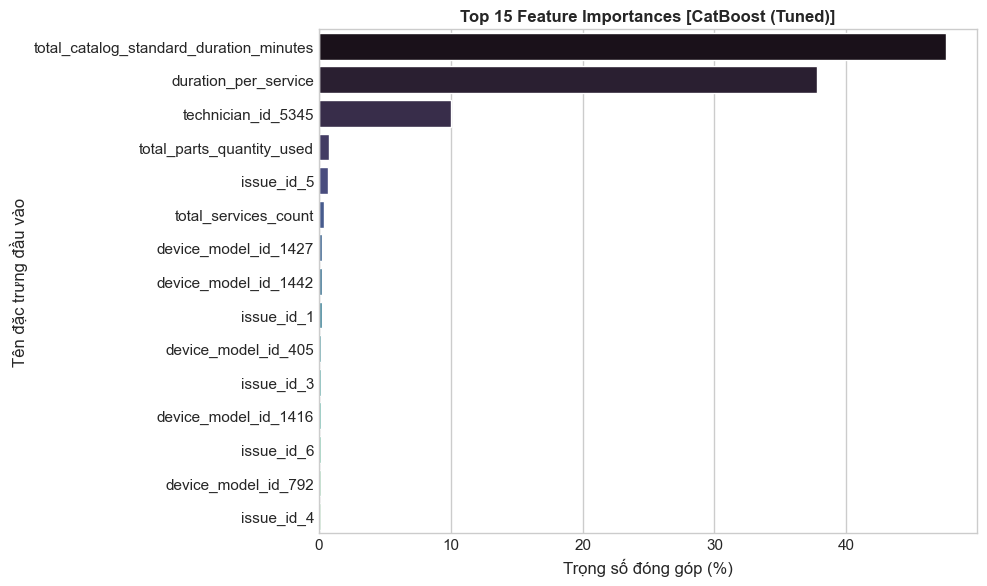

In [86]:
import pandas as pd

# Chọn CatBoost (Tuned) làm mô hình chiến thắng chính thức
best_model_obj = best_cb

importances = best_model_obj.feature_importances_
feat_imp_df = (
    pd.DataFrame({"Feature": X_train_clean.columns, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feat_imp_df, palette="mako")
plt.title(
    "Top 15 Feature Importances [CatBoost (Tuned)]",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Trọng số đóng góp (%)")
plt.ylabel("Tên đặc trưng đầu vào")
plt.tight_layout()
plt.show()

## Bước 8: Đóng gói Mô hình Artifact (.pkl) Sẵn sàng Tích hợp Backend

**Ý nghĩa kỹ thuật (MLOps Standard):**
Mô hình có chỉ số $R^2$ cao nhất và $\text{MAE}$ thấp nhất sẽ được đóng gói bằng kỹ thuật Tuần tự hóa (Serialization) thông qua thư viện `joblib`. 

Tệp nhị phân `.pkl` xuất ra chứa đầy đủ cây quyết định và trọng số tối ưu, sẵn sàng nạp vào Backend API (FastAPI / Flask) để phục vụ dự báo Thời gian Thi công Thuần cho từng phiếu sửa chữa trong môi trường vận hành thực tế (Production).

In [87]:
import joblib
from pathlib import Path

# Tạo thư mục lưu trữ model artifact
model_dir = Path("../models/experimental")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "best_repair_duration_model.pkl"
joblib.dump(best_model_obj, model_path)

print(f"--> [SUCCESS] Đã lưu mô hình CatBoost (Tuned) thành công!")
print(f"--> Path: {model_path.resolve()}")

--> [SUCCESS] Đã lưu mô hình CatBoost (Tuned) thành công!
--> Path: D:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\models\experimental\best_repair_duration_model.pkl
